Libraries imported successfully!
UCI dataset downloaded successfully!

Dataset shape: (5572, 2)

First 5 messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64
Preprocessing completed!
  label                                      clean_message
0   ham  go until jurong point crazy available only in ...
1   ham                            ok lar joking wif u oni
2  spam  free entry in a wkly comp to win fa cup final ...
3   ham        u dun say so early hor u c already then say
4   ham  nah i dont think he goes to usf he lives aroun...

Dataset shape after removing duplicates: (5169, 3)
Training samples: 4135
Testing samples: 1034
TF-IDF conversion completed!
Training feature shape: (4135, 5000)
Testing feature shape: (1034, 5000)

Decision Tree completed!

KNN completed!

SVM completed!

Naive Bayes completed!

MODEL COMPARISON RESULTS


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.9574,0.8321,0.8321,0.8321
1,KNN,0.9613,0.9333,0.7481,0.8305
2,SVM,0.9749,0.9565,0.8397,0.8943
3,Naive Bayes,0.9700,1.0000,0.7634,0.8658


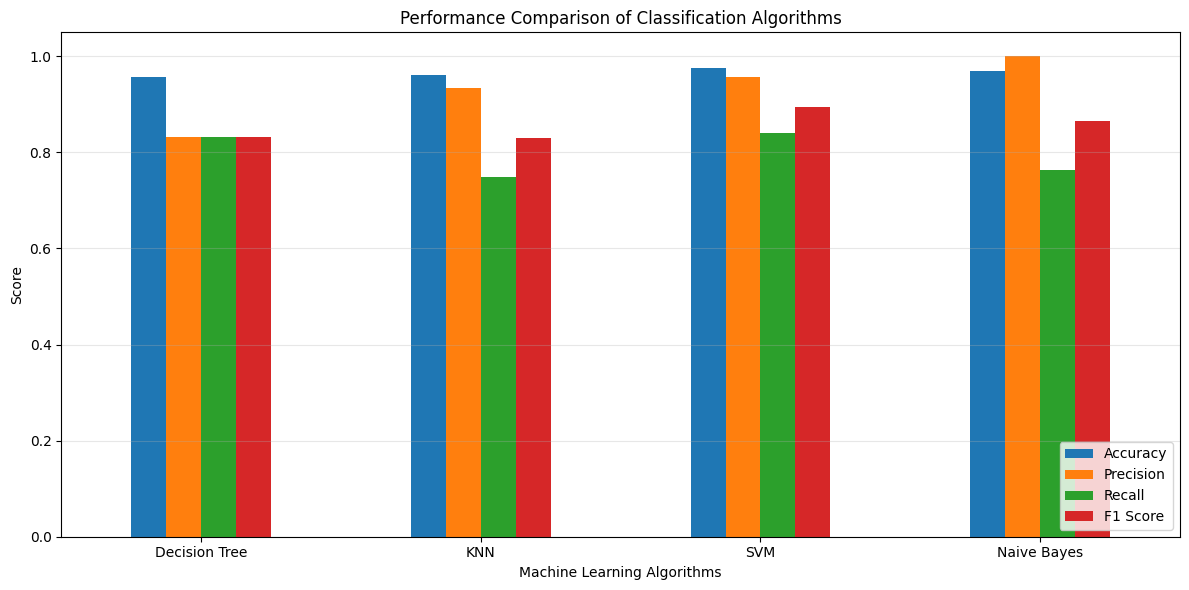

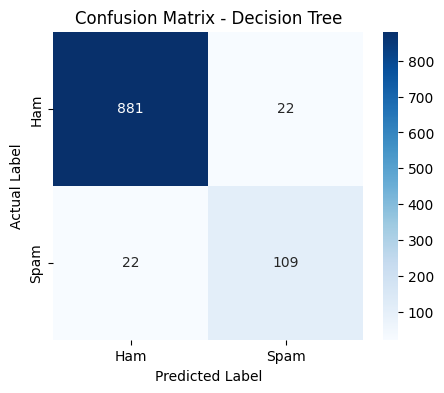


Classification Report - Decision Tree
              precision    recall  f1-score   support

         ham       0.98      0.98      0.98       903
        spam       0.83      0.83      0.83       131

    accuracy                           0.96      1034
   macro avg       0.90      0.90      0.90      1034
weighted avg       0.96      0.96      0.96      1034



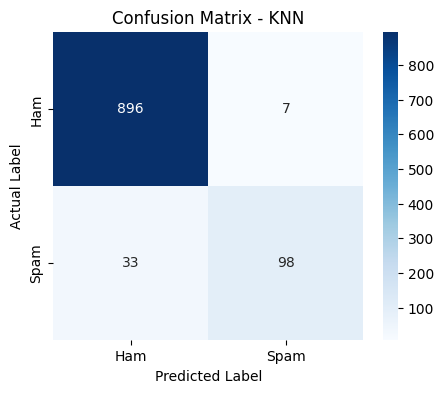


Classification Report - KNN
              precision    recall  f1-score   support

         ham       0.96      0.99      0.98       903
        spam       0.93      0.75      0.83       131

    accuracy                           0.96      1034
   macro avg       0.95      0.87      0.90      1034
weighted avg       0.96      0.96      0.96      1034



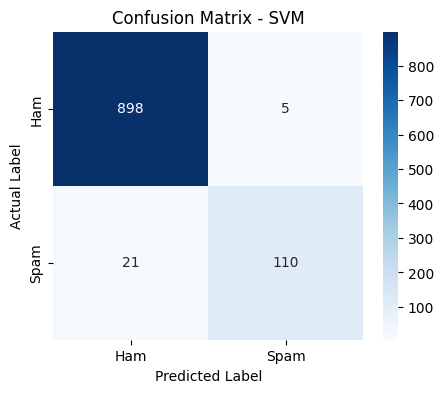


Classification Report - SVM
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.96      0.84      0.89       131

    accuracy                           0.97      1034
   macro avg       0.97      0.92      0.94      1034
weighted avg       0.97      0.97      0.97      1034



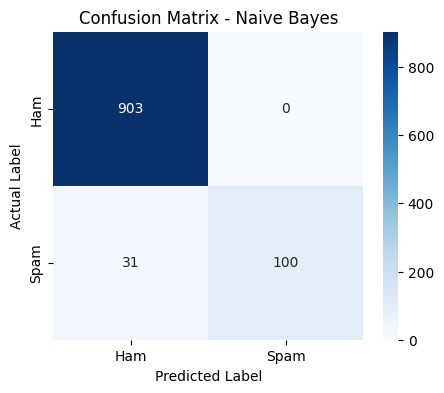


Classification Report - Naive Bayes
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       1.00      0.76      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034

BEST PERFORMING ALGORITHM
Algorithm: SVM
Accuracy: 0.9749
Precision: 0.9565
Recall: 0.8397
F1 Score: 0.8943
WHAT-IF EXPERIMENT RESULTS


,C Value,Accuracy,Precision,Recall,F1 Score
0,0.1,0.962282,0.969388,0.725191,0.829694
1,1.0,0.974855,0.956522,0.839695,0.894309
2,10.0,0.970986,0.910569,0.854962,0.881890


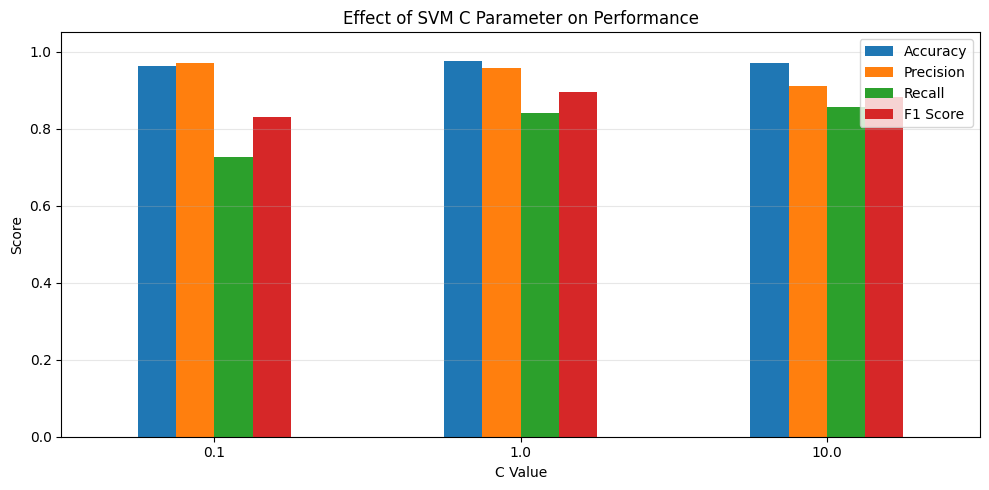

Results exported successfully!


In [6]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import zipfile
import urllib.request
import io

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


import pandas as pd
import requests
import zipfile
import io

# Download the original UCI SMS Spam dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

try:
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        filename = next(
            name for name in z.namelist()
            if name.endswith("SMSSpamCollection")
        )

        with z.open(filename) as file:
            df = pd.read_csv(
                file,
                sep="\t",
                header=None,
                names=["label", "message"],
                encoding="utf-8"
            )

    print("UCI dataset downloaded successfully!")

except Exception as e:
    print("UCI download failed:", e)
    print("Trying backup dataset...")

    backup_url = (
        "https://raw.githubusercontent.com/"
        "justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
    )

    df = pd.read_csv(
        backup_url,
        sep="\t",
        header=None,
        names=["label", "message"]
    )

    print("Backup dataset loaded successfully!")

print("\nDataset shape:", df.shape)
print("\nFirst 5 messages:")
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())


def clean_text(text):

    text = text.lower()

    text = re.sub(r'http\S+|www\S+', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text


df = df.drop_duplicates(subset="message").copy()

df["clean_message"] = df["message"].apply(clean_text)

print("Preprocessing completed!")
print(df[["label", "clean_message"]].head())

print("\nDataset shape after removing duplicates:",
      df.shape)

X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training feature shape:",
      X_train_tfidf.shape)

print("Testing feature shape:",
      X_test_tfidf.shape)

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        pos_label="spam",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        pos_label="spam",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        pos_label="spam",
        zero_division=0
    )

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"\n{name} completed!")

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON RESULTS")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Classification Algorithms")

plt.ylabel("Score")

plt.xlabel("Machine Learning Algorithms")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")

    plt.xlabel("Predicted Label")

    plt.ylabel("Actual Label")

    plt.show()

    print(f"\nClassification Report - {name}")

    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("BEST PERFORMING ALGORITHM")

print("Algorithm:", best_model["Algorithm"])

print("Accuracy:", round(best_model["Accuracy"], 4))

print("Precision:", round(best_model["Precision"], 4))

print("Recall:", round(best_model["Recall"], 4))

print("F1 Score:", round(best_model["F1 Score"], 4))

C_values = [0.1, 1.0, 10.0]

what_if_results = []

for c in C_values:

    svm_model = LinearSVC(
        C=c,
        random_state=42,
        max_iter=5000
    )

    svm_model.fit(
        X_train_tfidf,
        y_train
    )

    pred = svm_model.predict(
        X_test_tfidf
    )

    what_if_results.append({
        "C Value": c,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            pos_label="spam",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            pos_label="spam",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred,
            pos_label="spam",
            zero_division=0
        )
    })

what_if_df = pd.DataFrame(what_if_results)

print("WHAT-IF EXPERIMENT RESULTS")

display(what_if_df)

what_if_df.set_index("C Value").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Effect of SVM C Parameter on Performance")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

what_if_df.to_csv(
    "what_if_experiment_results.csv",
    index=False
)

print("Results exported successfully!")